In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Iris Dataset

This notebook aims to analyse one of the most common datasets popular in machine learning - "Iris Species".

## Preparation

Let's download data set

In [2]:
#Load environment vars
import os
from dotenv import load_dotenv

load_dotenv()

True

In [3]:
import shutil
import kagglehub
from kagglehub import KaggleDatasetAdapter
from pathlib import Path

DATASET_NAME = "uciml/iris"
DIRECTORY = Path("data")
DIRECTORY.mkdir(exist_ok=True)
DATASET_PATH = DIRECTORY / "iris.csv"

try:

    cache_dir = Path(kagglehub.dataset_download("uciml/iris"))
    print(list(cache_dir.iterdir()))  # check the actual file name

    shutil.copy(cache_dir / "Iris.csv", DATASET_PATH)

    print(f"Successully loaded dataset to {DATASET_PATH}")

except Exception as err:

    print(f"Failed to load dataset: ", err)


/Users/romanplakhotniuk/python/iris_dataset/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[PosixPath('/Users/romanplakhotniuk/.cache/kagglehub/datasets/uciml/iris/versions/2/database.sqlite'), PosixPath('/Users/romanplakhotniuk/.cache/kagglehub/datasets/uciml/iris/versions/2/Iris.csv')]
Successully loaded dataset to data/iris.csv


# Explaratory Data Analysis

Firstly, let's analyse the dataset to find any correlations and patterns.

In [4]:
df = pd.read_csv(DATASET_PATH)
n = 5
print("Shape: ", df.shape)
display(f"First {n} rows: ", df.head(n))

Shape:  (150, 6)


'First 5 rows: '

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


In [6]:
display("Numerical: ", df.describe(exclude=[str]))
unique_species = df["Species"].unique()
display("Unique species: ", unique_species)

for spec in unique_species:
    display(f"Info about species: {spec}", df[df["Species"] == spec].describe())

'Numerical: '

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


'Unique species: '

<ArrowStringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str

'Info about species: Iris-setosa'

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,50.00000,50.00000,50.000000,50.000000,50.00000
mean,25.50000,5.00600,3.418000,1.464000,0.24400
std,14.57738,0.35249,0.381024,0.173511,0.10721
min,1.00000,4.30000,2.300000,1.000000,0.10000
25%,13.25000,4.80000,3.125000,1.400000,0.20000
50%,25.50000,5.00000,3.400000,1.500000,0.20000
75%,37.75000,5.20000,3.675000,1.575000,0.30000
max,50.00000,5.80000,4.400000,1.900000,0.60000


'Info about species: Iris-versicolor'

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,50.00000,50.000000,50.000000,50.000000,50.000000
mean,75.50000,5.936000,2.770000,4.260000,1.326000
std,14.57738,0.516171,0.313798,0.469911,0.197753
min,51.00000,4.900000,2.000000,3.000000,1.000000
25%,63.25000,5.600000,2.525000,4.000000,1.200000
50%,75.50000,5.900000,2.800000,4.350000,1.300000
75%,87.75000,6.300000,3.000000,4.600000,1.500000
max,100.00000,7.000000,3.400000,5.100000,1.800000


'Info about species: Iris-virginica'

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,50.00000,50.00000,50.000000,50.000000,50.00000
mean,125.50000,6.58800,2.974000,5.552000,2.02600
std,14.57738,0.63588,0.322497,0.551895,0.27465
min,101.00000,4.90000,2.200000,4.500000,1.40000
25%,113.25000,6.22500,2.800000,5.100000,1.80000
50%,125.50000,6.50000,3.000000,5.550000,2.00000
75%,137.75000,6.90000,3.175000,5.875000,2.30000
max,150.00000,7.90000,3.800000,6.900000,2.50000


In [7]:
display("Has null values: ", df.isnull().any().any())

'Has null values: '

np.False_

## Univariate Analysis

Now, when we have briefly met with the dataset, let's analyse each column.

In [23]:
numeric = df.select_dtypes(include=[np.number]).drop(columns=["Id"])
cols = numeric.columns
n_cols = cols.size
print("Numeric parameters: ", n_cols)

Numeric parameters:  4


### Distributions of numerical data

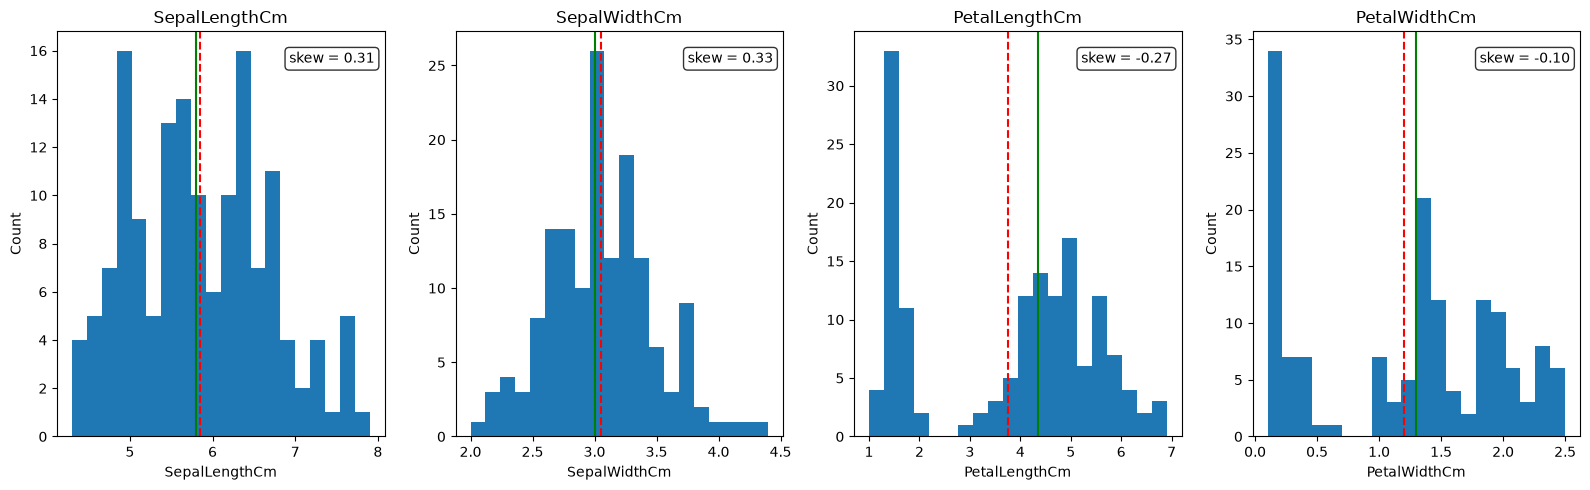

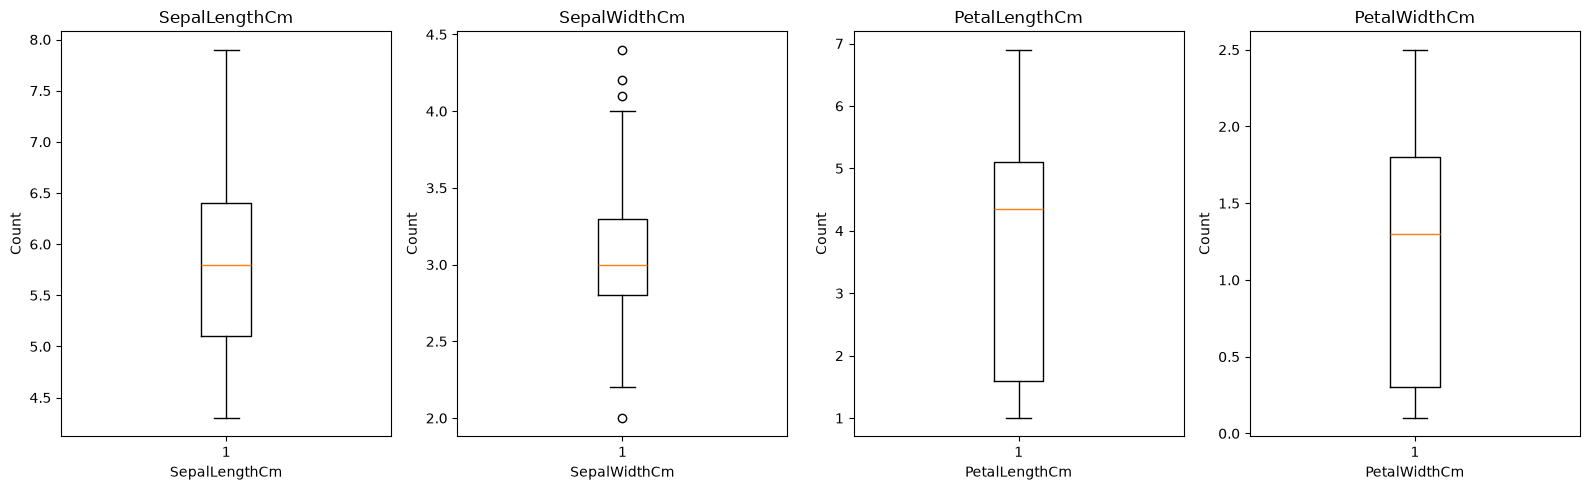

In [45]:
fig, axes = plt.subplots(ncols=n_cols, figsize=(16, 5))
for ax, col in zip(axes, cols):
    values = numeric[col]
    skew_val = values.skew()

    ax.hist(values, bins=20)
    ax.axvline(values.mean(), color="red", linestyle="--", label="mean")
    ax.axvline(values.median(), color="green", linestyle="-", label="median")
    
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

    ax.text(
        0.97, 0.95, f"skew = {skew_val:.2f}",
        transform=ax.transAxes, ha="right", va="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(ncols=n_cols, figsize=(16, 5))
for ax, col in zip(axes, cols):
    ax.boxplot(numeric[col])
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


### Justification

- Distributions of Sepal Length and Sepal Width are very close to each other.
- Distributions of Peral Length and Petal Width are very similar too.

## Bivariate Analysis

When we know distribution of each variable, let's try to analyse then in pairs.

### Numeric vs Numeric

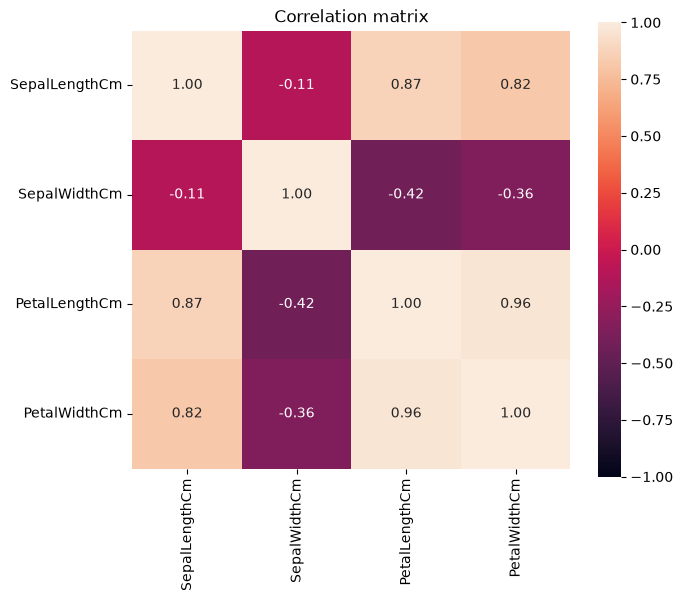

In [38]:
correlations = numeric.corr(method="pearson")

plt.figure(figsize=(7, 6))
sns.heatmap(correlations, annot=True, fmt=".2f", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()


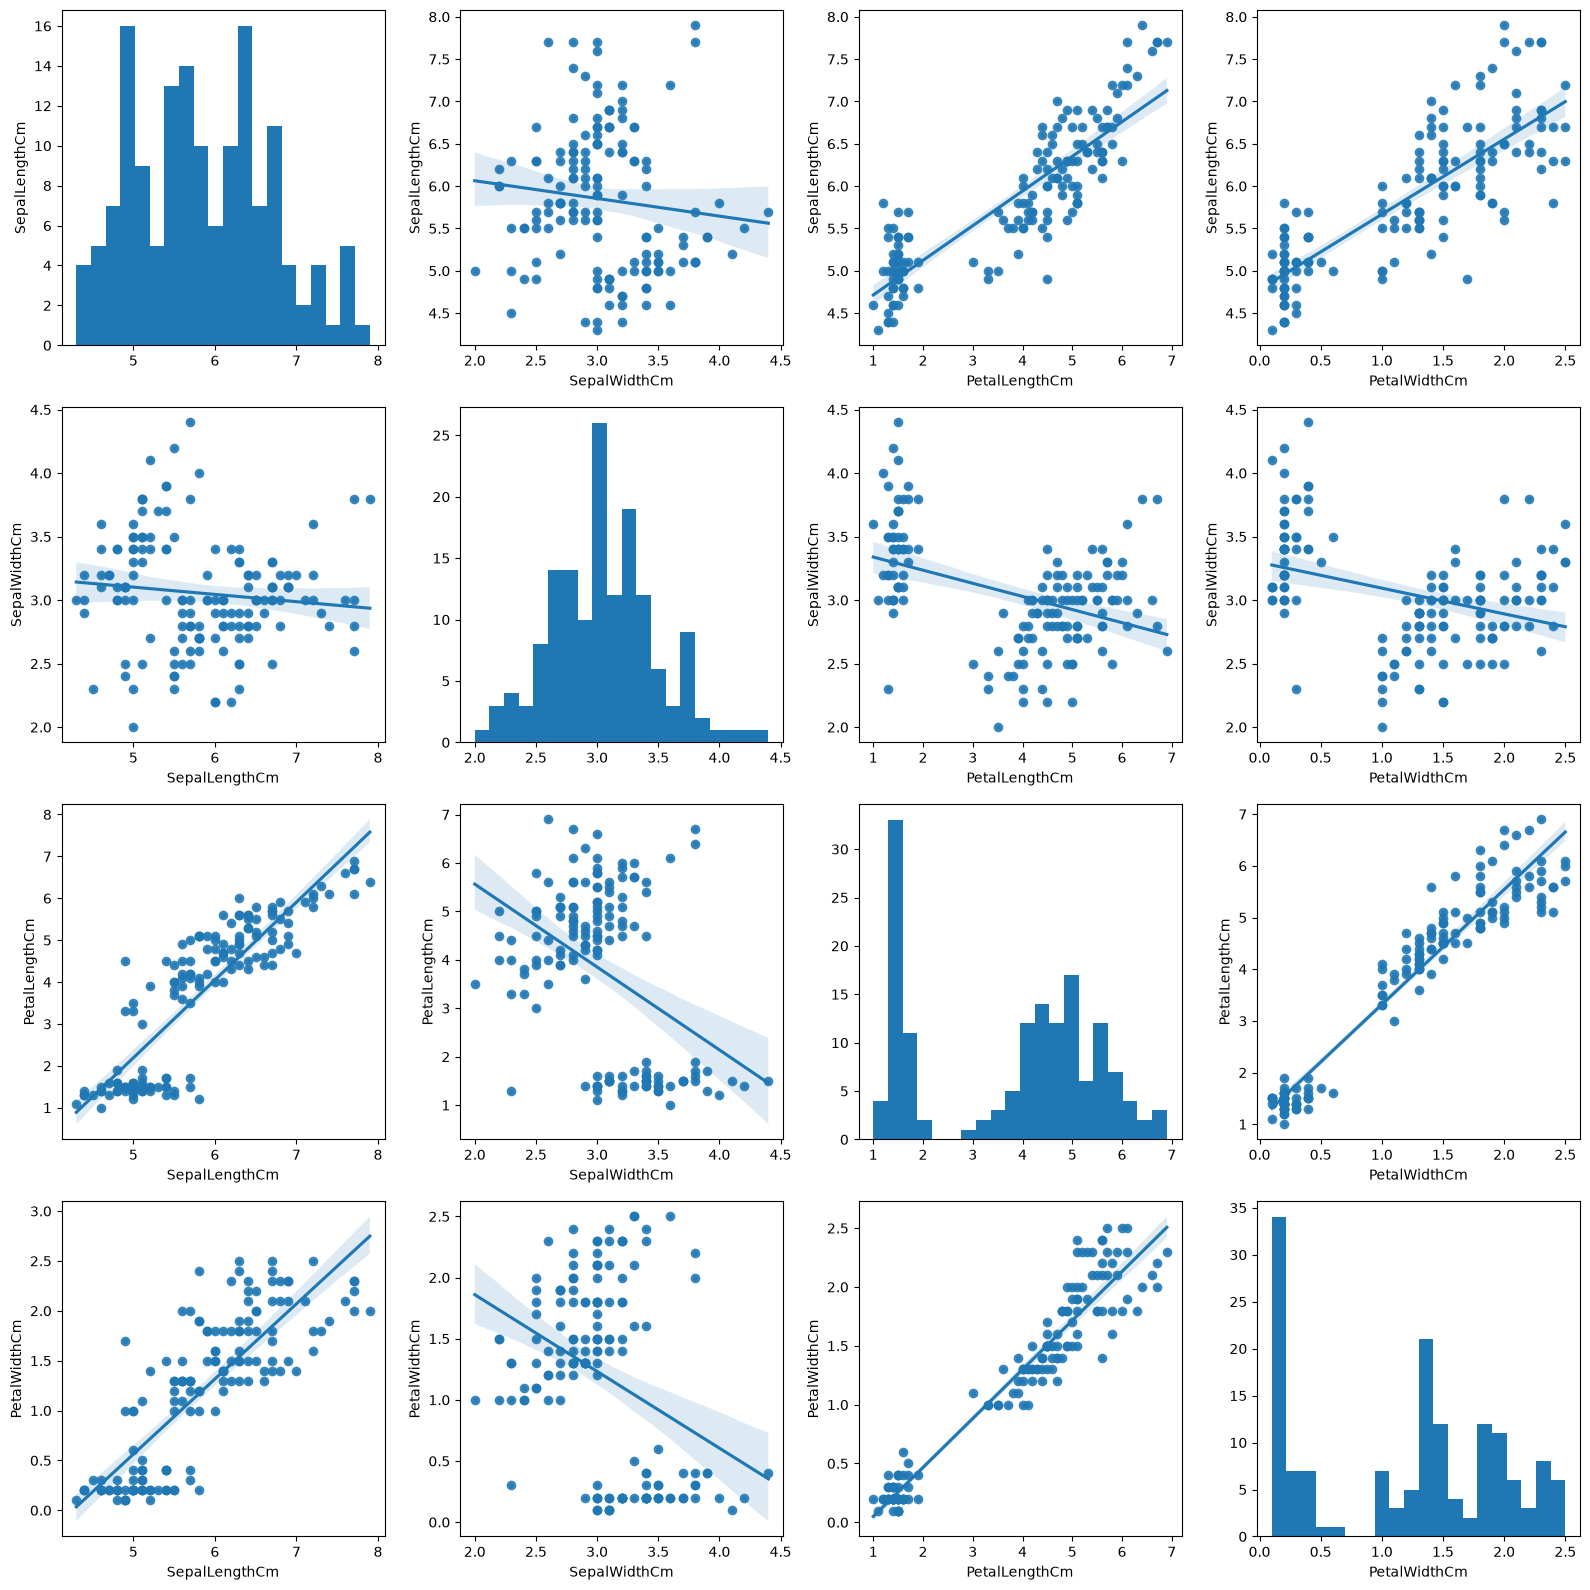

In [43]:
n = n_cols
fig, axes = plt.subplots(nrows=n, ncols=n, figsize=(16, 16))

for i, y_col in enumerate(cols):
    for j, x_col in enumerate(cols):
        ax = axes[i, j]
        if i == j:
            ax.hist(numeric[x_col], bins=20)
        else:
            ax.scatter(numeric[x_col], numeric[y_col], s=10, alpha=0.7)
            sns.regplot(x=numeric[x_col], y=numeric[y_col], ax=ax)

        if i == n - 1:
            ax.set_xlabel(x_col)

        if j == 0:
            ax.set_ylabel(y_col)

plt.tight_layout()
plt.show()

#### Justification

Correlation heat map and scatter plots demonstrate several dependencies between numeric variables:

Following pairs show linear patterns:

- SepalLength & PetalLength
- SepalLength & PetalWidth
- PetaLength & PetalWidth


### Categorical vs Numeric

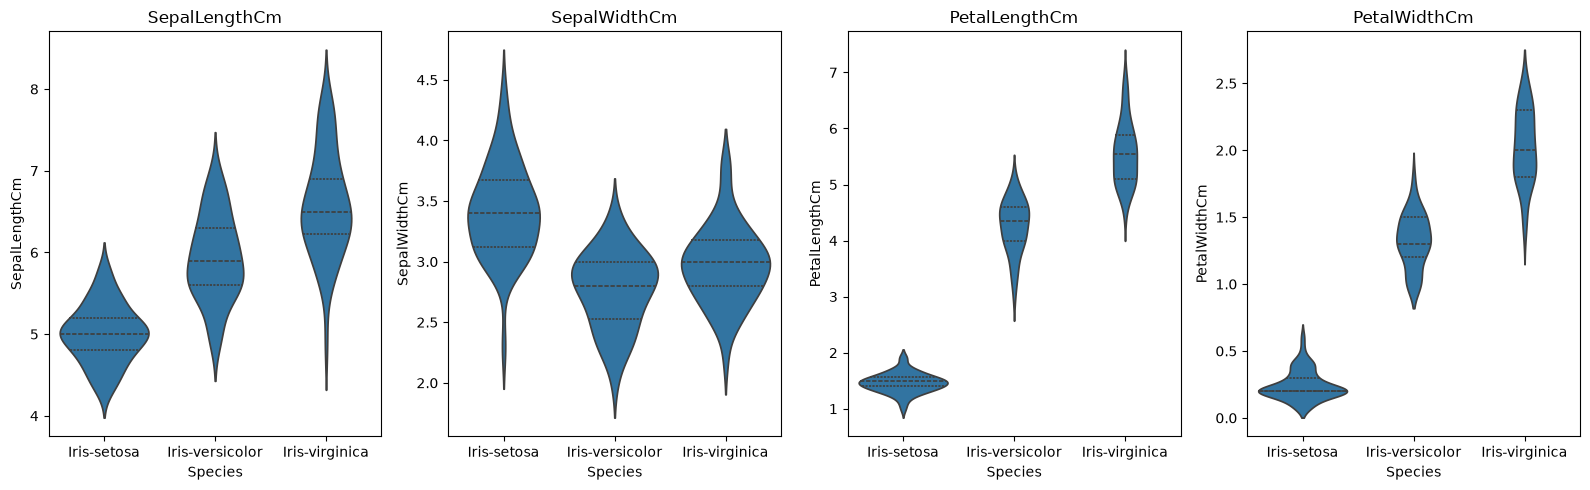

In [50]:
fig, axes = plt.subplots(ncols=len(cols), figsize=(16, 5))
for ax, col in zip(axes, cols):
    sns.violinplot(data=df, x="Species", y=col, ax=ax, inner="quartile")
    ax.set_title(col)
plt.tight_layout()
plt.show()

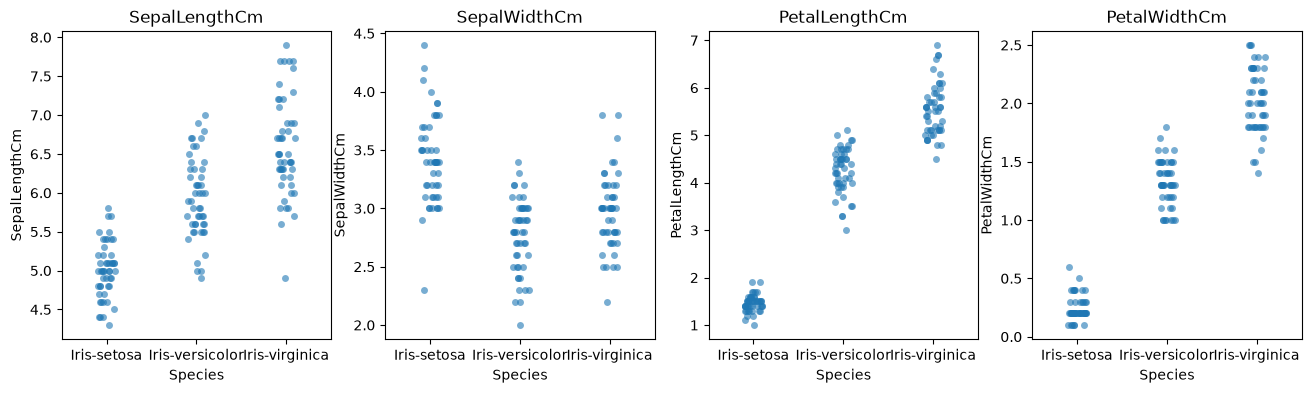

In [53]:
fig, axes = plt.subplots(ncols=len(cols), figsize=(16, 4))
for ax, col in zip(axes, cols):
    sns.stripplot(data=df, x="Species", y=numeric[col], jitter=True, alpha=0.6, ax=ax)
    ax.set_title(col)
plt.show()

#### Conclusions from this plot

- Petal length and width alone would classify Setosa perfectly and Versicolor vs. Virginica with only a few borderline cases.
- Sepal width shouldn’t be relied on for classification by itself.
- The hardest boundary is between Versicolor and Virginica on sepal length and width, so a classifier’s errors will concentrate there.
- Within-group spread differs: Setosa is compact on petal features, while Virginica is more variable on sepal length. Unequal spread matters if you use methods that assume equal variances.

# Preprocessing

We have found primary correlations and now it is the best momemnt to prepare the data for machine learning.